In [1]:
## a useful function to generate a data list for further analysis
import os
data_list=[]
input_path = 'Z:/DATA/experiment_trackball_Optomotor'
dataset=os.listdir(input_path)
#exp_date=['220813','220811','220814']
#exp_date=['221015','221016']
#exp_date=['221102','221103']
#exp_date=['221102','221103','221015','221016']
exp_date=['230824']
exp_name='dots'
for locust in dataset:
    locust_directory=input_path + '/' + locust
    if os.path.isdir(locust_directory):
        file_list = os.listdir(locust_directory)
        for thisDate in file_list:
            if thisDate in exp_date:
                experiment_directory=locust_directory + '/' + thisDate
                experiment_list=os.listdir(experiment_directory)
                for thisExperiment in experiment_list:
                    if thisExperiment in exp_name:
                        data_list.append(experiment_directory + '/' + exp_name)

In [2]:
from curate_trackball_database import generate_curated_database
from analyse_stimulus_evoked_response import main

In [3]:
json_file = "analysis_methods_dictionary.json"

In [ ]:
# because the import does not update the new version of python.
# Need to restart kernel 
output0_across_exp=[]
output1_across_exp=[]
output2_across_exp=[]
for this_dir in data_list:
    test,speed_list,travel_distance=main(this_dir,json_file)
    output0_across_exp.append(test)
    output1_across_exp.append(speed_list)
    output2_across_exp.append(travel_distance)

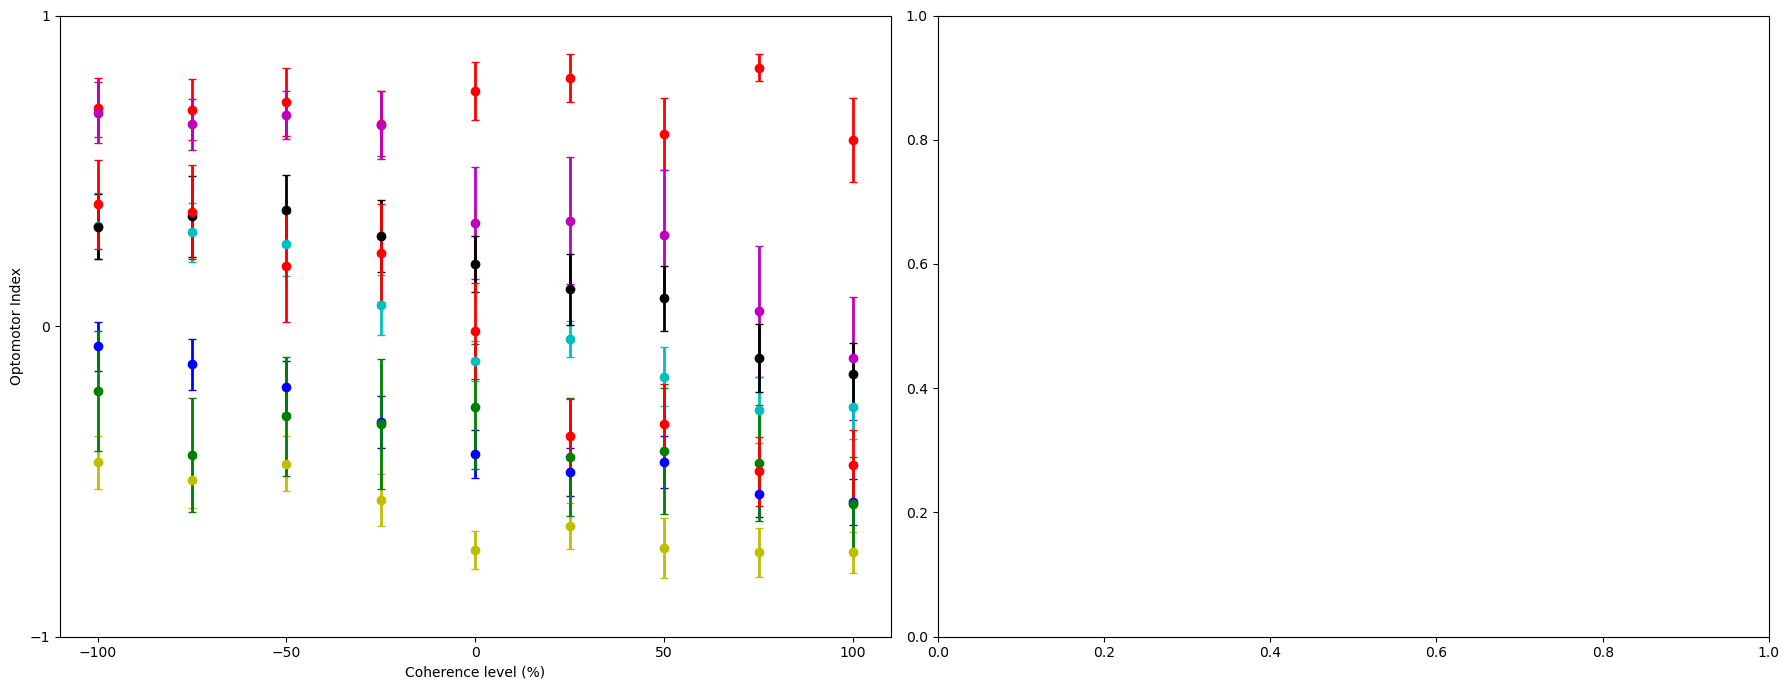

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
colormap = np.array(["r", "y", "m", "c", "k", "b", "g", "r"])
fig2, (ax3, ax4) = plt.subplots(
    nrows=1, ncols=2, figsize=(18, 7), tight_layout=True
)
for i in range(len(output0_across_exp)):
    this_animal = output0_across_exp[i]
    tmp=this_animal.groupby("coherence_level").count()
    follow_count_coherence = tmp.index.values
    for j in range(len(this_animal.groupby("coherence_level"))):
        this_coherence=follow_count_coherence[j]
        this_response = this_animal.loc[
            this_animal["coherence_level"] == this_coherence, "opto_index"
        ].values
        # this_coherence = x_axis_value_running_trials[i]
        mean_response = np.mean(this_response, axis=0)
        sem_response = np.std(this_response, axis=0, ddof=1) / np.sqrt(
            this_response.shape[0]
        )
        ax3.errorbar(
            this_coherence,
            mean_response,
            yerr=sem_response,
            c=colormap[i],
            fmt="o",
            elinewidth=2,
            capsize=3,
        )
    ax3.set_ylim(-1, 1)
    # ax3.set_yticks([-1, 0, 1])
    ax3.set(
        yticks=[-1, 0, 1],
        ylabel="Optomotor Index",
        xticks=[100, 50, 0, -50, -100],
        xlabel="Coherence level (%)",)
    # ax4.scatter(follow_count_coherence, follow_count, c=colormap[0], marker="o")
    # ax4.set_ylim(0, 15)
    # ax4.set(
    #     yticks=[0, 15],
    #     ylabel="Follow response (count)",
    #     xticks=[100, 50, 0, -50, -100],
    #     xlabel="Coherence level (%)",
    # )